 A Computational Model of Visual Saliency Using Neighbour Suppression

## Introduction

Visual saliency refers to the ability of the visual system to identify features that stand out from their surroundings. For example, a tilted bar among several vertical bars can be detected quickly because it differs from the surrounding elements.

This project explores a simplified computational model of visual pop-out, inspired by Li Zhaoping's 2002 work on a saliency map in primary visual cortex (V1).

The model uses orientation similarity and neighbourhood-based suppression to calculate the saliency of each bar and predict the location of the most distinctive bar.

## Objective

To investigate how orientation differences and the similarity parameter (sigma) affect the detection of a distinctive bar in a visual display.

## 1. Importing Libraries

In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
rng = np.random.default_rng(0)

## 2. Creating the Orientation Grid

In [18]:
def make_grid(n=10, odd_diff=30, noise_sd=3):
    """Return an n x n grid of orientations (degrees) and the odd bar's (row, col)."""
    grid = np.zeros((n, n))                      # all vertical
    r, c = rng.integers(0, n, size=2)            # random odd-bar location
    grid[r, c] = odd_diff                        # tilt one bar
    grid += rng.normal(0, noise_sd, size=(n, n)) # a little noise on every bar
    return grid, (r, c)


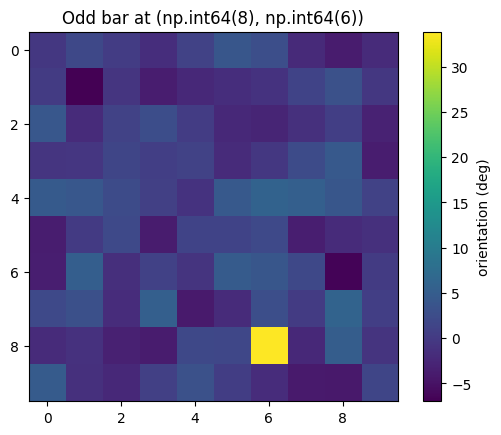

In [19]:
grid, target = make_grid()
plt.imshow(grid, cmap="viridis"); plt.colorbar(label="orientation (deg)")
plt.title(f"Odd bar at {target}"); plt.show()
response = np.ones_like(grid)

## 3. Calculating Orientation Similarity

In [20]:
def similarity(a, b, sigma=15):
    d = a - b
    return np.exp(-(d**2) / (2 * sigma**2))

## 4. Original Suppression Method

In [21]:
def calculate_suppression_total(grid, r, c, sigma=15):
    total = 0

    for i in range(r - 1, r + 2):
        for j in range(c - 1, c + 2):

            if i == r and j == c:
                continue

            if i < 0 or i >= grid.shape[0]:
                continue

            if j < 0 or j >= grid.shape[1]:
                continue

            sim = similarity(grid[r, c], grid[i, j], sigma=sigma)
            total += sim

    return total

## 5. Modified Suppression Method: Average Neighbour Similarity

In [22]:



def calculate_suppression(grid, r, c, sigma=15):
    total = 0
    count = 0

    for i in range(r - 1, r + 2):
        for j in range(c - 1, c + 2):

            if i == r and j == c:
                continue

            if i < 0 or i >= grid.shape[0]:
                continue

            if j < 0 or j >= grid.shape[1]:
                continue

            sim = similarity(grid[r, c], grid[i, j], sigma=sigma)

            total += sim
            count += 1

    return total / count if count > 0 else 0



### Modification: Averaging Neighbour Suppression

I changed the suppression calculation to divide the total similarity by the number of available neighbours. This calculates the average suppression for each bar, rather than allowing the number of neighbours to determine the total suppression.

## 6. Comparing Total and Average Suppression

In [23]:
# Compare total suppression and average suppression

positions = {
    "Corner": (0, 0),
    "Edge": (0, 5),
    "Middle": (5, 5)
}

for name, (r, c) in positions.items():

    total = calculate_suppression_total(grid, r, c)
    average = calculate_suppression(grid, r, c)

    print(name)
    print("Total suppression:", total)
    print("Average suppression:", average)
    print()

Corner
Total suppression: 2.895835478674975
Average suppression: 0.9652784928916583

Edge
Total suppression: 4.7830750495163254
Average suppression: 0.9566150099032651

Middle
Total suppression: 7.869440353706631
Average suppression: 0.9836800442133289



## 7. Controlled Comparison: Corner, Edge and Middle

In [24]:
# Controlled comparison using identical orientations

test_grid = np.zeros((10, 10))

positions = {
    "Corner": (0, 0),
    "Edge": (0, 5),
    "Middle": (5, 5)
}

for name, (r, c) in positions.items():
    total = calculate_suppression_total(test_grid, r, c)
    average = calculate_suppression(test_grid, r, c)

    print(name)
    print("Total:", total)
    print("Average:", average)
    print()

Corner
Total: 3.0
Average: 1.0

Edge
Total: 5.0
Average: 1.0

Middle
Total: 8.0
Average: 1.0



### Observation: Edge Effect

Initially, I calculated suppression by adding the similarity values of all neighbouring bars. However, I noticed that corner and edge bars had fewer neighbours than bars in the middle. As a result, they received lower total suppression, which could make them appear more salient.

To address this, I modified the calculation to average suppression over the available neighbours instead of using the total. This reduced the difference in suppression caused by the number of neighbours.

## 8. Testing Suppression Values

In [25]:
target_r, target_c = target

print("Target suppression:",
      calculate_suppression(grid, target_r, target_c))

print("Ordinary bar suppression:",
      calculate_suppression(grid, 0, 0))

Target suppression: 0.07422291955360309
Ordinary bar suppression: 0.9652784928916583


## 9. Generating the Suppression Map

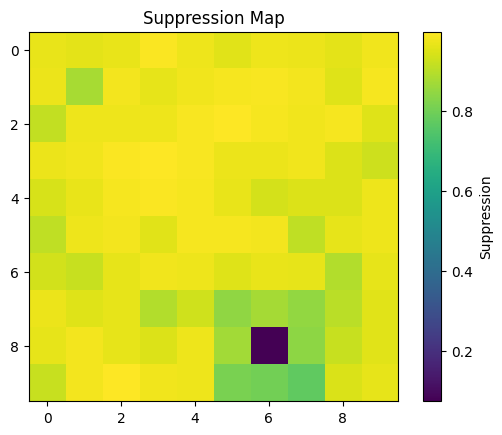

In [26]:

suppression = np.zeros_like(grid)

for r in range(grid.shape[0]):
    for c in range(grid.shape[1]):
        suppression[r, c] = calculate_suppression(grid, r, c)

plt.imshow(suppression, cmap="viridis")
plt.colorbar(label="Suppression")
plt.title("Suppression Map")
plt.show()


## 10. Calculating the Saliency Map

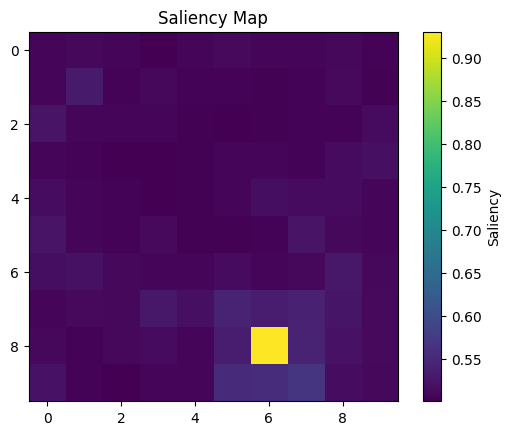

In [27]:

saliency = response / (1 + suppression)

plt.imshow(saliency, cmap="viridis")
plt.colorbar(label="Saliency")
plt.title("Saliency Map")
plt.show()


## 11. Predicting the Target Location

In [28]:

predicted = np.unravel_index(
    np.argmax(saliency), saliency.shape
)

print("Actual target:", target)
print("Predicted target:", predicted)
print("Correct prediction:", predicted == target)


Actual target: (np.int64(8), np.int64(6))
Predicted target: (np.int64(8), np.int64(6))
Correct prediction: True


## 12. Experiment 1 and Experiment 2: Orientation Difference and Sigma

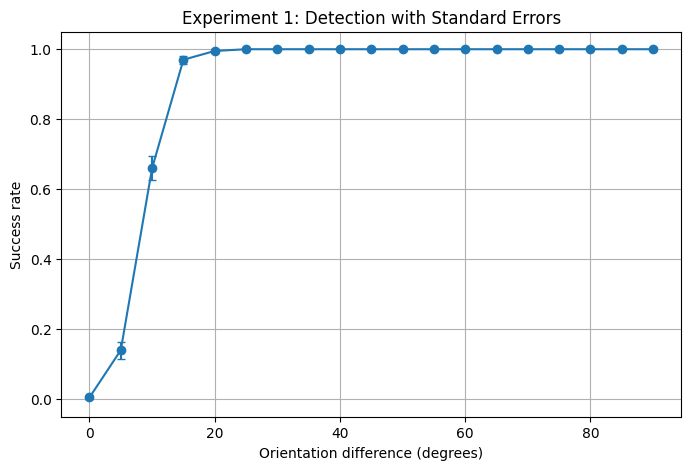

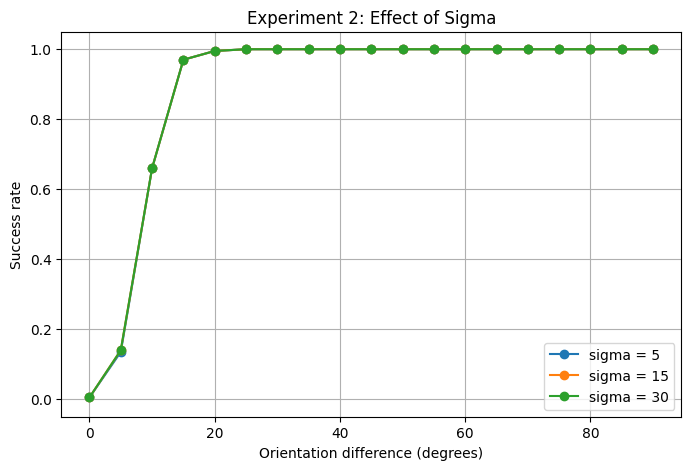

Chance-level check (0 degrees):
Sigma 5: 0.5%
Sigma 15: 0.5%
Sigma 30: 0.5%


In [29]:



# Experiment settings
orientation_diffs = list(range(0, 91, 5))
trials = 200
sigma_values = [5, 15, 30]

# Generate the same displays for all sigma values
datasets = {}

for diff in orientation_diffs:
    datasets[diff] = []

    for trial in range(trials):
        grid, target = make_grid(
            odd_diff=diff,
            noise_sd=3
        )

        # Constant response for every bar
        response = np.ones_like(grid)

        datasets[diff].append((grid, target, response))


# Predict the target location
def predict(grid, sigma, response):
    suppression = np.zeros_like(grid)

    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            suppression[r, c] = calculate_suppression(
                grid, r, c, sigma=sigma
            )

    # Calculate saliency
    saliency = response / (1 + suppression)

    # Return the location with maximum saliency
    return np.unravel_index(
        np.argmax(saliency), saliency.shape
    )


# Run experiments
results = {}

for sigma in sigma_values:
    rates = []

    for diff in orientation_diffs:
        correct = 0

        for grid, target, response in datasets[diff]:
            predicted = predict(grid, sigma, response)

            if predicted == target:
                correct += 1

        rates.append(correct / trials)

    results[sigma] = rates


# Experiment 1: Detection accuracy with standard error bars
p_values = results[15]

standard_errors = [
    np.sqrt(p * (1 - p) / trials)
    for p in p_values
]

plt.figure(figsize=(8, 5))

plt.errorbar(
    orientation_diffs,
    p_values,
    yerr=standard_errors,
    marker="o",
    capsize=3
)

plt.xlabel("Orientation difference (degrees)")
plt.ylabel("Success rate")
plt.title("Experiment 1: Detection with Standard Errors")
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.show()


# Experiment 2: Compare different sigma values
plt.figure(figsize=(8, 5))

for sigma in sigma_values:
    plt.plot(
        orientation_diffs,
        results[sigma],
        marker="o",
        label=f"sigma = {sigma}"
    )

plt.xlabel("Orientation difference (degrees)")
plt.ylabel("Success rate")
plt.title("Experiment 2: Effect of Sigma")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True)
plt.show()


# Chance-level check at 0 degrees
print("Chance-level check (0 degrees):")

for sigma in sigma_values:
    print(
        f"Sigma {sigma}: "
        f"{results[sigma][0] * 100:.1f}%"
    )


### Checking Similarity at Different Sigma Values

In [30]:

print(similarity(0, 10, sigma=5))
print(similarity(0, 10, sigma=15))
print(similarity(0, 10, sigma=30))

0.1353352832366127
0.8007374029168081
0.9459594689067654


## 13. Fine Experiment: Effect of Sigma with Response Noise

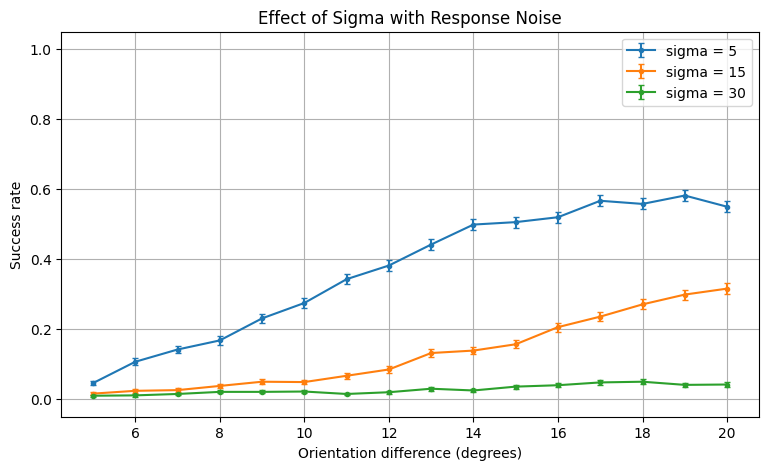

In [31]:


# Experiment settings
fine_diffs = list(range(5, 21, 1))
fine_trials = 1000
fine_sigmas = [5, 15, 30]

# Store results separately from your earlier experiments
fine_results = {}

# Generate the same displays for all sigma values
fine_datasets = {}

for diff in fine_diffs:
    fine_datasets[diff] = []

    for trial in range(fine_trials):
        grid, target = make_grid(
            odd_diff=diff,
            noise_sd=3
        )

        # Generate response noise once per display
        response = np.maximum(
            0.01,
            1 + rng.normal(0, 0.2, grid.shape)
        )

        fine_datasets[diff].append(
            (grid, target, response)
        )

# Evaluate all sigma values on the same displays
for sigma in fine_sigmas:
    success_rates = []

    for diff in fine_diffs:
        correct = 0

        for grid, target, response in fine_datasets[diff]:
            predicted = predict(grid, sigma, response)

            if predicted == target:
                correct += 1

        success_rates.append(correct / fine_trials)

    fine_results[sigma] = success_rates

# Plot curves with standard error bars
plt.figure(figsize=(9, 5))

for sigma in fine_sigmas:
    rates = fine_results[sigma]

    errors = [
        np.sqrt(p * (1 - p) / fine_trials)
        for p in rates
    ]

    plt.errorbar(
        fine_diffs,
        rates,
        yerr=errors,
        marker="o",
        markersize=3,
        capsize=2,
        label=f"sigma = {sigma}"
    )

plt.xlabel("Orientation difference (degrees)")
plt.ylabel("Success rate")
plt.title("Effect of Sigma with Response Noise")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True)
plt.show()


## Limitations

- The model is a simplified computational demonstration of visual pop-out, not a complete model of the human visual system.
- Orientation differences are calculated using direct subtraction. The model does not yet account for the circular nature of orientation, where 0° and 180° represent the same orientation.
- The model uses a simplified neighbourhood-based suppression mechanism and does not include all biological processes involved in visual perception.
- The response noise used in the fine experiment is randomly generated and does not represent measured biological data.